# Proyecto agro: análisis y modelado de rendimiento de cebada

Este cuaderno documenta la evolución del proyecto desde la exploración inicial hasta la mejora del modelo base.

## Qué hicimos
- Revisamos la estructura de la carpeta y clasificamos los archivos por utilidad.
- Identificamos que el conjunto principal para la línea base era `Conjunto_datos_PRO_AgroCebada.csv` y el objetivo era `ID_area_rendimiento_70_30_Reto_AgroCebada.csv`.
- Diagnosticar el problema de calidad de datos: filas con nubosidad total, fechas inválidas, valores atípicos y variables con datos no observables.
- Construimos una tabla agregada por parcela para convertir un panel temporal irregular en una muestra útil para modelado supervisado.
- Entrenamos un modelo base de regresión y luego lo mejoramos incorporando características temporales del comportamiento del NDVI, LAI y MSAVI por parcela.

## Por qué se hizo así
La clave del problema no era simplemente “limpiar CSV”; era convertir observaciones diarias por polígonos en indicadores por parcela. Así se redujo el ruido temporal y se convirtió el problema en una tarea de regresión en nivel de parcela, que es la unidad con rendimiento real asociado.

## Orden del trabajo
1. Carga y diagnóstico inicial de los archivos.
2. Limpieza de filas no válidas y tratamiento de valores nulos.
3. EDA para entender la distribución, la variabilidad y los patrones del rendimiento.
4. Agregado por `ID_POLIGONO` con estadísticas por parcela.
5. Ajuste de modelos base.
6. Mejora con variables temporales y validación cruzada.
7. Preparación para la incorporación controlada de datos extra (BÁSICO, clima y topografía).

## Resultado actual
La mejora del modelo base fue efectiva: el error absoluto disminuyó respecto a la línea base inicial, principalmente porque añadimos señales de evolución temporal por parcela y no solo promedios estáticos.

En la siguiente etapa se recomienda incorporar datos del conjunto BÁSICO de forma separada por sensor antes de combinar clima o variables geográficas.


Analisis exploratorio del archivo "Conjunto_datos_PRO_AgroCebada.csv"

Librerias a utilizar

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ETL:

In [2]:
pro = pd.read_csv("DATASET_RETO_AGRO_2026/Conjunto_datos_PRO_AgroCebada.csv",
    parse_dates=["fecha_captura"],
    dayfirst=True
)

rendimiento = pd.read_csv(
    "DATASET_RETO_AGRO_2026/ID_area_rendimiento_70_30_Reto_AgroCebada.csv"
)




In [3]:
pro.shape
pro.head()
pro.info()
pro.describe()
pro.head(20)

<class 'pandas.DataFrame'>
RangeIndex: 47804 entries, 0 to 47803
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   ID_POLIGONO           47804 non-null  str           
 1   fecha_captura         47804 non-null  datetime64[us]
 2   sensor                47804 non-null  str           
 3   ndvi_promedio         35747 non-null  float64       
 4   ndvi_std              35747 non-null  float64       
 5   ndvi_max              35747 non-null  float64       
 6   ndvi_min              35747 non-null  float64       
 7   evi_promedio          35747 non-null  float64       
 8   evi_std               35747 non-null  float64       
 9   evi_max               35747 non-null  float64       
 10  evi_min               35747 non-null  float64       
 11  lai_promedio          35747 non-null  float64       
 12  lai_std               35747 non-null  float64       
 13  lai_max               35747

,ID_POLIGONO,fecha_captura,sensor,ndvi_promedio,ndvi_std,ndvi_max,ndvi_min,evi_promedio,evi_std,evi_max,evi_min,lai_promedio,lai_std,lai_max,lai_min,msavi_promedio,msavi_std,msavi_max,msavi_min,porcentaje_nubosidad
0,AGC_056,2025-02-05,Planet,0.300,0.042,0.553,0.175,0.138,0.022,0.251,0.068,1.049,0.182,2.144,0.586,0.135,0.022,0.244,0.066,0.000
1,AGC_056,2025-02-08,Planet,0.204,0.043,0.529,0.125,0.110,0.018,0.209,0.074,0.697,0.167,1.888,0.247,0.110,0.018,0.207,0.072,0.000
2,AGC_056,2025-02-07,Planet,0.241,0.043,0.534,0.154,0.134,0.018,0.224,0.098,0.826,0.159,1.858,0.404,0.135,0.018,0.230,0.098,0.000
3,AGC_056,2025-02-09,Planet,0.246,0.039,0.536,0.153,0.142,0.018,0.243,0.098,0.818,0.159,1.849,0.399,0.141,0.018,0.237,0.095,0.000
4,AGC_056,2025-01-30,Planet,0.211,0.046,0.533,0.113,0.110,0.020,0.229,0.069,0.724,0.187,1.955,0.277,0.111,0.021,0.230,0.067,0.000
5,AGC_056,2025-02-02,Planet,0.271,0.044,0.535,0.183,0.131,0.025,0.263,0.085,0.939,0.168,1.946,0.528,0.126,0.024,0.248,0.082,0.000
6,AGC_056,2025-02-04,Planet,0.255,0.043,0.536,0.165,0.119,0.022,0.240,0.078,0.971,0.178,2.110,0.505,0.113,0.021,0.227,0.076,0.000
7,AGC_056,2025-02-03,Planet,0.268,0.054,0.518,0.078,0.082,0.040,0.239,0.012,0.998,0.220,2.056,-0.011,0.076,0.039,0.229,0.011,80.034
8,AGC_056,2025-08-02,Planet,0.433,0.051,0.686,0.269,0.302,0.041,0.488,0.187,1.492,0.175,2.334,1.000,0.292,0.039,0.488,0.185,0.000
9,AGC_056,2025-02-17,Planet,0.224,0.034,0.447,0.150,0.128,0.016,0.208,0.089,0.625,0.138,1.401,0.247,0.126,0.016,0.201,0.088,0.000


In [4]:
faltantes = (
    pro.isna()
       .mean()
       .mul(100)
       .sort_values(ascending=False)
)

faltantes

ndvi_promedio           25.221739
ndvi_min                25.221739
ndvi_max                25.221739
ndvi_std                25.221739
lai_std                 25.221739
lai_max                 25.221739
lai_min                 25.221739
evi_promedio            25.221739
evi_std                 25.221739
evi_max                 25.221739
evi_min                 25.221739
lai_promedio            25.221739
msavi_std               25.221739
msavi_max               25.221739
msavi_min               25.221739
msavi_promedio          25.221739
sensor                   0.000000
fecha_captura            0.000000
ID_POLIGONO              0.000000
porcentaje_nubosidad     0.000000
dtype: float64

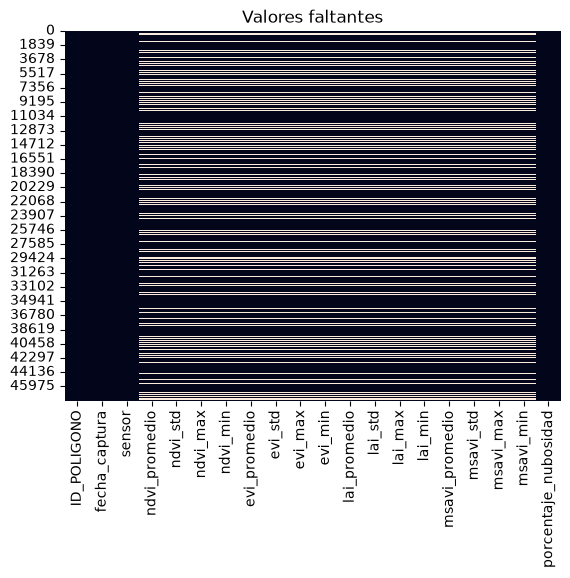

In [5]:
sns.heatmap(pro.isna(), cbar=False)
plt.title("Valores faltantes")
plt.show()

Analizis de las fechas

In [6]:
pro["fecha_captura"].min(), pro["fecha_captura"].max()
pro["fecha_captura"].dt.month.value_counts().sort_index()

fecha_captura
1     4316
2     4135
3     5166
4     4760
5     4436
6     2213
7     2940
8     4381
9     3964
10    3561
11    3407
12    4525
Name: count, dtype: int64

Observaciones x mes

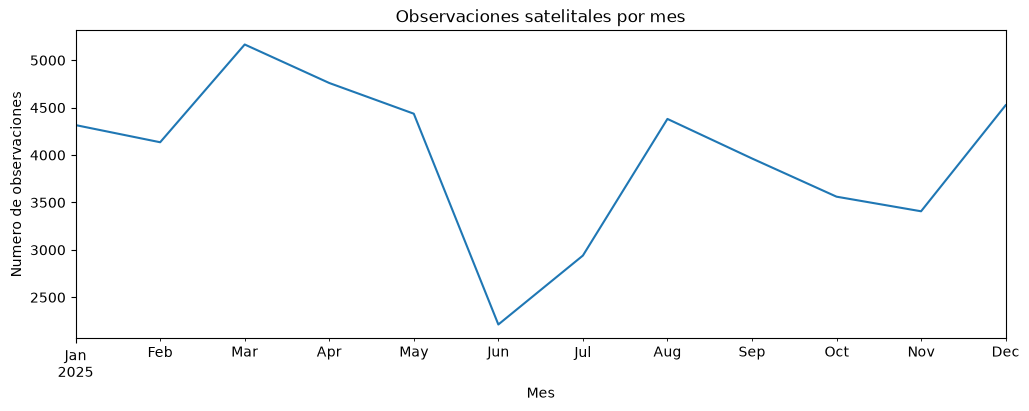

In [7]:
observaciones_mes = (
    pro.groupby(pro["fecha_captura"].dt.to_period("M"))
       .size()
)

observaciones_mes.plot(figsize=(12, 4))
plt.title("Observaciones satelitales por mes")
plt.xlabel("Mes")
plt.ylabel("Numero de observaciones")
plt.show()

Indices satelitales

In [8]:
indices = [
    "ndvi_promedio",
    "evi_promedio",
    "lai_promedio",
    "msavi_promedio"
]

pro[indices].describe()

,ndvi_promedio,evi_promedio,lai_promedio,msavi_promedio
count,35747.000000,35747.000000,35747.000000,35747.000000
mean,0.353691,0.214637,1.215302,0.211447
std,0.174964,0.123494,0.612512,0.122765
min,0.007000,0.028000,-0.112000,0.010000
25%,0.227000,0.133000,0.785000,0.129000
50%,0.275000,0.160000,0.962000,0.157000
75%,0.451000,0.252000,1.499000,0.251000
max,0.907000,0.877000,3.663000,0.780000


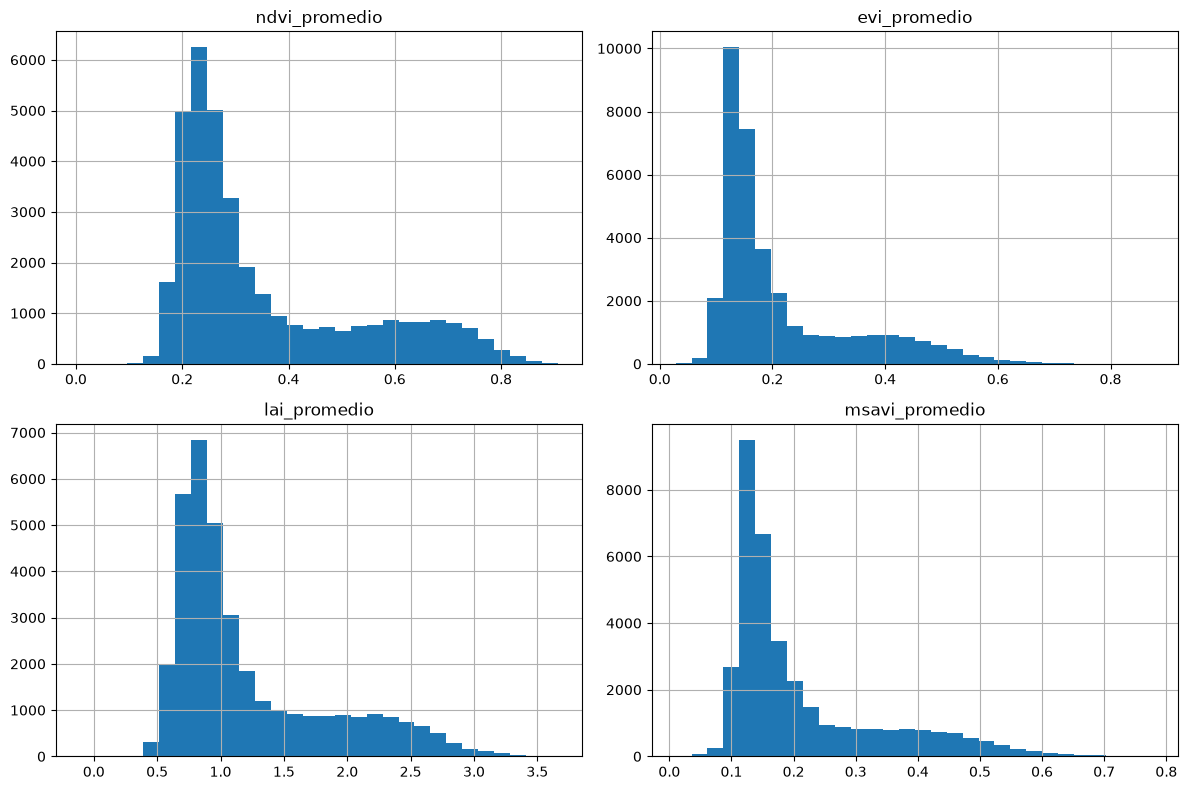

In [9]:
pro[indices].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

Valores extremos:

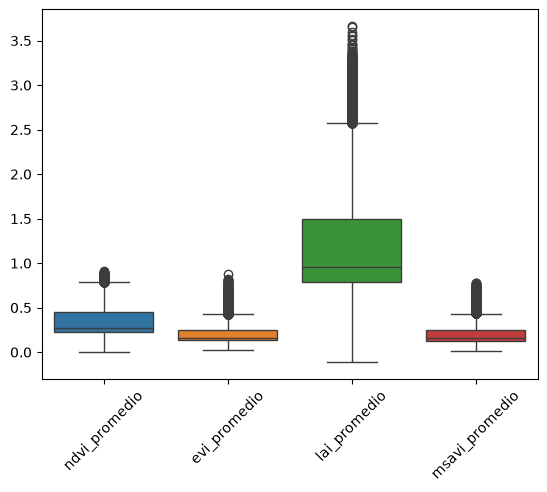

In [10]:
sns.boxplot(data = pro[indices])
plt.xticks(rotation=45)
plt.show()


Evolucion de cada parcela:

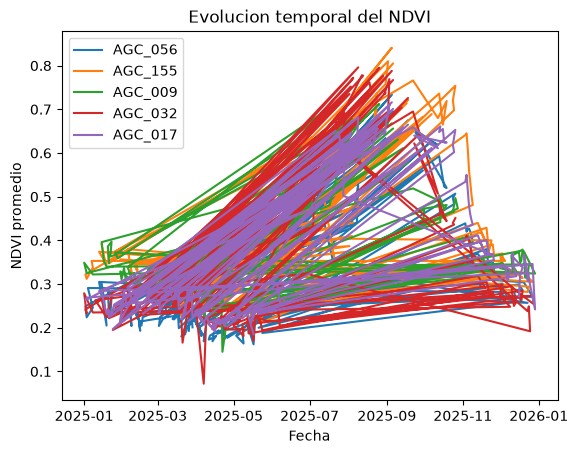

In [11]:
parcelas = pro["ID_POLIGONO"].drop_duplicates().head(5)

for parcela in parcelas:
    datos = pro[pro["ID_POLIGONO"] == parcela]
    plt.plot(
        datos["fecha_captura"],
        datos["ndvi_promedio"],
        label=parcela
    )

plt.legend()
plt.title("Evolucion temporal del NDVI")
plt.xlabel("Fecha")
plt.ylabel("NDVI promedio")
plt.show()

Periodos de crecimiento entre los meses: 07 - 11
Caidas repentinas: Inicios de años y primeros meses del año


Tabla de rendimiento:


In [12]:
datos = pro.merge(
    rendimiento,
    on="ID_POLIGONO",
    how="left"
)

datos.head()

,ID_POLIGONO,fecha_captura,sensor,ndvi_promedio,ndvi_std,ndvi_max,ndvi_min,evi_promedio,evi_std,evi_max,...,lai_min,msavi_promedio,msavi_std,msavi_max,msavi_min,porcentaje_nubosidad,AREA_HA,RENDIMIENTO_T_HA,CONJUNTO,Unnamed: 4
0,AGC_056,2025-02-05,Planet,0.300,0.042,0.553,0.175,0.138,0.022,0.251,...,0.586,0.135,0.022,0.244,0.066,0.0,3.65,5.07,ENTRENAMIENTO,NaN
1,AGC_056,2025-02-08,Planet,0.204,0.043,0.529,0.125,0.110,0.018,0.209,...,0.247,0.110,0.018,0.207,0.072,0.0,3.65,5.07,ENTRENAMIENTO,NaN
2,AGC_056,2025-02-07,Planet,0.241,0.043,0.534,0.154,0.134,0.018,0.224,...,0.404,0.135,0.018,0.230,0.098,0.0,3.65,5.07,ENTRENAMIENTO,NaN
3,AGC_056,2025-02-09,Planet,0.246,0.039,0.536,0.153,0.142,0.018,0.243,...,0.399,0.141,0.018,0.237,0.095,0.0,3.65,5.07,ENTRENAMIENTO,NaN
4,AGC_056,2025-01-30,Planet,0.211,0.046,0.533,0.113,0.110,0.020,0.229,...,0.277,0.111,0.021,0.230,0.067,0.0,3.65,5.07,ENTRENAMIENTO,NaN


In [13]:
entrenamiento = datos[datos["CONJUNTO"] == "ENTRENAMIENTO"].copy()
prediccion = datos[datos["CONJUNTO"] == "PREDICCION"].copy()

In [14]:
resumen = (
    entrenamiento
    .groupby("ID_POLIGONO")
    .agg(
        ndvi_promedio=("ndvi_promedio", "mean"),
        ndvi_maximo=("ndvi_promedio", "max"),
        ndvi_minimo=("ndvi_promedio", "min"),
        evi_promedio=("evi_promedio", "mean"),
        lai_promedio=("lai_promedio", "mean"),
        msavi_promedio=("msavi_promedio", "mean"),
        nubosidad_promedio=("porcentaje_nubosidad", "mean"),
        area_ha=("AREA_HA", "first"),
        rendimiento=("RENDIMIENTO_T_HA", "first")
    )
    .reset_index()
)

Matriz de correlacion  para analizar relaciones con el rendimiento

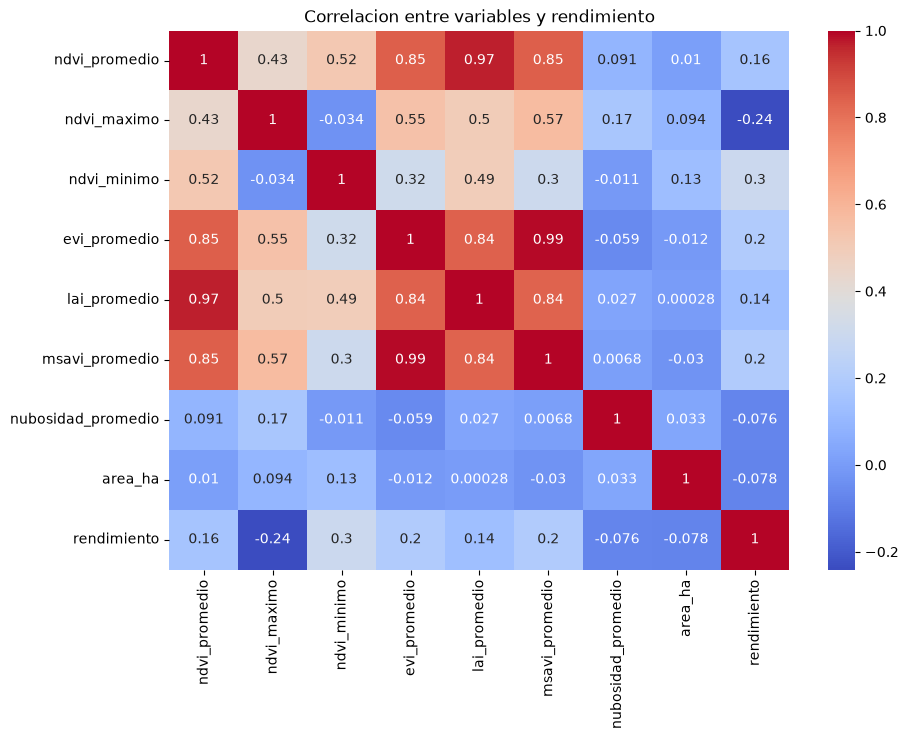

In [15]:
correlacion = resumen.select_dtypes("number").corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlacion, annot=True, cmap="coolwarm")
plt.title("Correlacion entre variables y rendimiento")
plt.show()

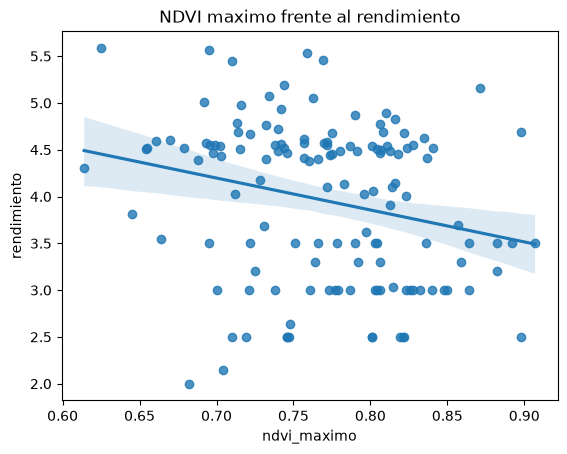

In [16]:
sns.regplot(
    data=resumen,
    x="ndvi_maximo",
    y="rendimiento"
)

plt.title("NDVI maximo frente al rendimiento")
plt.show()

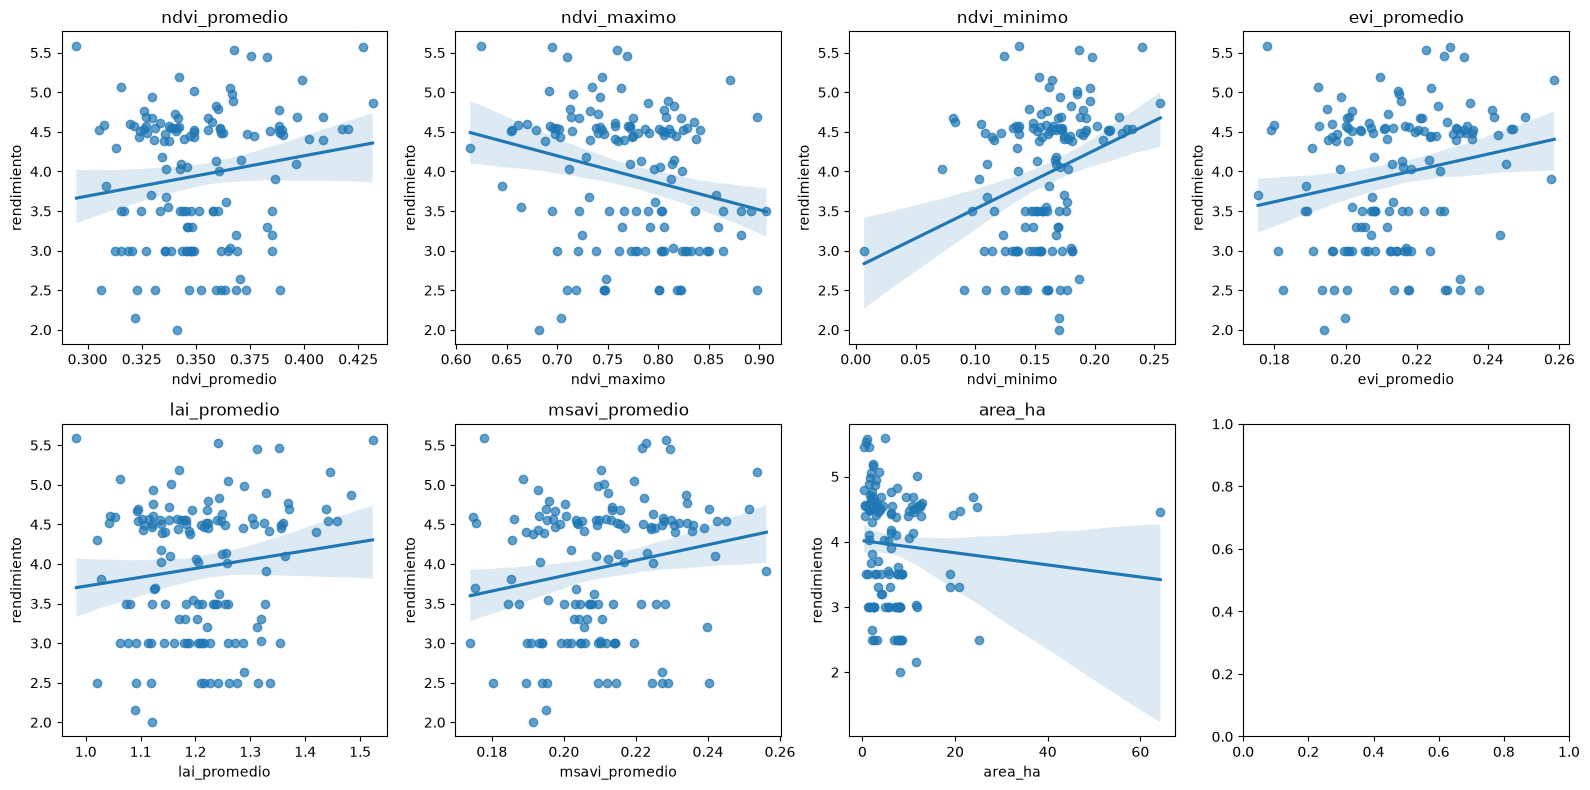

In [17]:
variables = [
    "ndvi_promedio",
    "ndvi_maximo",
    "ndvi_minimo",
    "evi_promedio",
    "lai_promedio",
    "msavi_promedio",
    "area_ha"
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax, variable in zip(axes, variables):
    sns.regplot(
        data=resumen,
        x=variable,
        y="rendimiento",
        ax=ax,
        scatter_kws={"alpha": 0.7}
    )
    ax.set_title(variable)

plt.tight_layout()
plt.show()

## Limpieza y diagnóstico de calidad
Esta sección identifica valores faltantes, duplicados, valores fuera de rango y posibles valores atípicos. No elimina registros automáticamente: primero se documentan para decidir el tratamiento.

In [18]:
# Copia de trabajo: se conservan los datos originales en `pro`
pro_limpieza = pro.copy()

# Asegurar tipos básicos y ordenar el panel temporal
pro_limpieza["fecha_captura"] = pd.to_datetime(
    pro_limpieza["fecha_captura"],
    dayfirst=True,
    errors="coerce"
 )
columnas_numericas = pro_limpieza.select_dtypes(include=np.number).columns
pro_limpieza[columnas_numericas] = pro_limpieza[columnas_numericas].apply(
    pd.to_numeric, errors="coerce"
 )
pro_limpieza = pro_limpieza.sort_values(["ID_POLIGONO", "fecha_captura"])

print("Filas:", len(pro_limpieza))
print("Parcelas:", pro_limpieza["ID_POLIGONO"].nunique())
print("Fechas inválidas:", pro_limpieza["fecha_captura"].isna().sum())
display(pro_limpieza.head())

Filas: 47804
Parcelas: 197
Fechas inválidas: 0


,ID_POLIGONO,fecha_captura,sensor,ndvi_promedio,ndvi_std,ndvi_max,ndvi_min,evi_promedio,evi_std,evi_max,evi_min,lai_promedio,lai_std,lai_max,lai_min,msavi_promedio,msavi_std,msavi_max,msavi_min,porcentaje_nubosidad
43071,AGC_001,2025-01-01,Planet,0.242,0.024,0.382,0.182,0.144,0.014,0.228,0.103,0.838,0.102,1.433,0.521,0.144,0.015,0.222,0.102,0.0
43072,AGC_001,2025-01-03,Planet,0.212,0.022,0.322,0.104,0.128,0.014,0.192,0.059,0.784,0.095,1.367,0.269,0.127,0.014,0.195,0.057,0.0
43229,AGC_001,2025-01-05,Planet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0
43231,AGC_001,2025-01-06,Planet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0
43230,AGC_001,2025-01-07,Planet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0


### 1. Valores faltantes y duplicados
Primero distinguimos filas sin información satelital de valores faltantes aislados. Una fila con 100% de nubosidad y todos los índices vacíos debe marcarse como no utilizable, no rellenarse automáticamente.

In [19]:
indices_principales = [
    "ndvi_promedio", "evi_promedio", "lai_promedio", "msavi_promedio"
 ]

reporte_faltantes = pd.DataFrame({
    "faltantes": pro_limpieza[indices_principales].isna().sum(),
    "porcentaje": pro_limpieza[indices_principales].isna().mean().mul(100).round(2)
}).sort_values("porcentaje", ascending=False)

pro_limpieza["fila_sin_indices"] = pro_limpieza[indices_principales].isna().all(axis=1)
pro_limpieza["fila_nubosidad_total"] = pro_limpieza["porcentaje_nubosidad"].eq(100)
pro_limpieza["fila_utilizable"] = ~pro_limpieza["fila_sin_indices"]

print("Filas sin ningún índice:", pro_limpieza["fila_sin_indices"].sum())
print("Filas con nubosidad del 100%:", pro_limpieza["fila_nubosidad_total"].sum())
print("Filas utilizables:", pro_limpieza["fila_utilizable"].sum())
display(reporte_faltantes)

duplicados = pro_limpieza.duplicated(
    subset=["ID_POLIGONO", "fecha_captura"],
    keep=False
 )
print("Duplicados parcela-fecha:", duplicados.sum())
display(pro_limpieza.loc[duplicados, ["ID_POLIGONO", "fecha_captura"]].head(10))

Filas sin ningún índice: 12057
Filas con nubosidad del 100%: 12057
Filas utilizables: 35747


,faltantes,porcentaje
ndvi_promedio,12057,25.22
evi_promedio,12057,25.22
lai_promedio,12057,25.22
msavi_promedio,12057,25.22


Duplicados parcela-fecha: 0


,ID_POLIGONO,fecha_captura


### 2. Valores atípicos y rangos plausibles
El método IQR detecta observaciones extremas respecto a la distribución. Además, se revisan rangos físicos básicos. Un atípico no se elimina automáticamente: puede ser un error o una condición agrícola real.

In [21]:
datos_validos = pro_limpieza.loc[pro_limpieza["fila_utilizable"]].copy()

def conteo_atipicos_iqr(dataframe, columnas):
    resultados = []
    for columna in columnas:
        serie = dataframe[columna].dropna()
        q1 = serie.quantile(0.25)
        q3 = serie.quantile(0.75)
        iqr = q3 - q1
        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr
        mask = (serie < limite_inferior) | (serie > limite_superior)
        resultados.append({
            "variable": columna,
            "atipicos_iqr": int(mask.sum()),
            "porcentaje": round(mask.mean() * 100, 2),
            "limite_inferior": round(limite_inferior, 3),
            "limite_superior": round(limite_superior, 3)
        })
    return pd.DataFrame(resultados).sort_values(
        "porcentaje", ascending=False
    )

reporte_iqr = conteo_atipicos_iqr(
    datos_validos,
    indices_principales + ["porcentaje_nubosidad"]
 )
display(reporte_iqr)

violaciones_rango = pd.DataFrame({
    "ndvi_fuera_de_rango": ~datos_validos["ndvi_promedio"].between(-1, 1),
    "evi_fuera_de_rango": ~datos_validos["evi_promedio"].between(-1, 1),
    "lai_negativo": datos_validos["lai_promedio"] < 0,
    "msavi_fuera_de_rango": ~datos_validos["msavi_promedio"].between(-1, 1),
    "nubosidad_fuera_de_rango": ~datos_validos["porcentaje_nubosidad"].between(0, 100)
})

print("Filas con alguna violación de rango:", violaciones_rango.any(axis=1).sum())
display(violaciones_rango.sum().sort_values(ascending=False).to_frame("filas"))

,variable,atipicos_iqr,porcentaje,limite_inferior,limite_superior
4,porcentaje_nubosidad,5430,15.19,0.000,0.000
1,evi_promedio,3345,9.36,-0.045,0.430
3,msavi_promedio,3073,8.60,-0.054,0.434
2,lai_promedio,1609,4.50,-0.286,2.570
0,ndvi_promedio,492,1.38,-0.109,0.787


Filas con alguna violación de rango: 1


,filas
lai_negativo,1
ndvi_fuera_de_rango,0
evi_fuera_de_rango,0
msavi_fuera_de_rango,0
nubosidad_fuera_de_rango,0


### 3. ¿Es una serie temporal?
Los datos tienen fecha y varias observaciones por parcela, por lo que son un **panel temporal**. La siguiente revisión comprueba si además forman series regulares.

Parcelas: 197
Intervalo mediano global: 1.0 días
Mayor intervalo observado: 19.0 días


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ID_POLIGONO,197,197,AGC_001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
observaciones,197.0,NaN,NaN,NaN,242.659898,233.0,240.0,243.0,246.0,251.0,4.418314
observaciones_utilizables,197.0,NaN,NaN,NaN,181.456853,149.0,176.0,185.0,189.0,202.0,11.018742
primera_fecha,197,NaN,NaN,NaN,2025-01-01 04:30:27.411167,2025-01-01 00:00:00,2025-01-01 00:00:00,2025-01-01 00:00:00,2025-01-01 00:00:00,2025-01-02 00:00:00,NaN
ultima_fecha,197,NaN,NaN,NaN,2025-12-29 09:15:31.979695,2025-12-29 00:00:00,2025-12-29 00:00:00,2025-12-29 00:00:00,2025-12-30 00:00:00,2025-12-30 00:00:00,NaN
intervalo_mediano_dias,197.0,NaN,NaN,NaN,1.0,1.0,1.0,1.0,1.0,1.0,0.0
intervalo_maximo_dias,197.0,NaN,NaN,NaN,14.213198,10.0,12.0,15.0,16.0,19.0,1.954907
porcentaje_utilizable,197.0,NaN,NaN,NaN,74.753198,63.03,72.84,75.81,77.14,82.45,3.927514


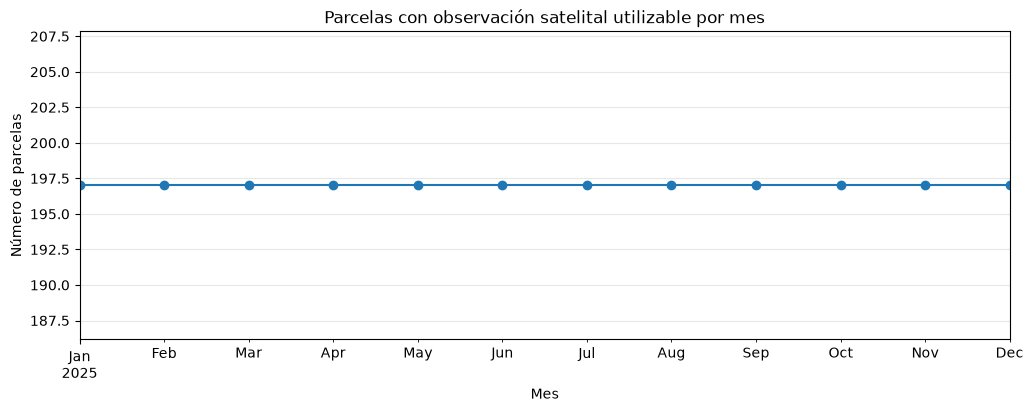

In [22]:
serie = pro_limpieza[["ID_POLIGONO", "fecha_captura", "fila_utilizable"]].copy()
serie["fecha"] = serie["fecha_captura"].dt.normalize()
serie = serie.sort_values(["ID_POLIGONO", "fecha"])
serie["intervalo_dias"] = serie.groupby("ID_POLIGONO")["fecha"].diff().dt.days

resumen_temporal = (
    serie.groupby("ID_POLIGONO")
    .agg(
        observaciones=("fecha", "size"),
        observaciones_utilizables=("fila_utilizable", "sum"),
        primera_fecha=("fecha", "min"),
        ultima_fecha=("fecha", "max"),
        intervalo_mediano_dias=("intervalo_dias", "median"),
        intervalo_maximo_dias=("intervalo_dias", "max")
    )
    .reset_index()
 )
resumen_temporal["porcentaje_utilizable"] = (
    resumen_temporal["observaciones_utilizables"]
    .div(resumen_temporal["observaciones"])
    .mul(100)
    .round(2)
 )

print("Parcelas:", len(resumen_temporal))
print("Intervalo mediano global:", serie["intervalo_dias"].median(), "días")
print("Mayor intervalo observado:", serie["intervalo_dias"].max(), "días")
display(resumen_temporal.describe(include="all").transpose())

# Número de parcelas con observación utilizable por mes
serie["mes"] = serie["fecha"].dt.to_period("M")
cobertura_mensual = (
    serie[serie["fila_utilizable"]]
    .groupby("mes")["ID_POLIGONO"]
    .nunique()
 )
cobertura_mensual.plot(figsize=(12, 4), marker="o")
plt.title("Parcelas con observación satelital utilizable por mes")
plt.xlabel("Mes")
plt.ylabel("Número de parcelas")
plt.grid(alpha=0.3)
plt.show()

### 4. Tabla de trabajo limpia
Se excluyen las filas sin índices válidos para el análisis satelital. El valor negativo de LAI se convierte en `NaN`, pero se conserva un conteo para documentar la decisión. No se interpolan automáticamente los huecos.

In [23]:
pro_analisis = pro_limpieza.loc[pro_limpieza["fila_utilizable"]].copy()
pro_analisis["lai_negativo_original"] = pro_analisis["lai_promedio"] < 0
pro_analisis.loc[pro_analisis["lai_negativo_original"], "lai_promedio"] = np.nan
pro_analisis["fecha_dia"] = pro_analisis["fecha_captura"].dt.normalize()

print("Filas para análisis:", len(pro_analisis))
print("LAI inválidos marcados:", pro_analisis["lai_negativo_original"].sum())
print("Nulos después de la limpieza:")
display(pro_analisis[indices_principales].isna().sum())

Filas para análisis: 35747
LAI inválidos marcados: 1
Nulos después de la limpieza:


ndvi_promedio     0
evi_promedio      0
lai_promedio      1
msavi_promedio    0
dtype: int64

## Primer modelo base
En esta etapa convertimos las observaciones diarias en una fila por parcela. Así evitamos que una parcela con más capturas pese más que otra y podemos relacionar sus características con el rendimiento.

### 1. Crear una fila por parcela
Usamos únicamente filas válidas de `pro_analisis`. Las variables agregadas describen el nivel medio, el máximo, el mínimo y la variabilidad observada durante el periodo. Esta es una línea base exploratoria; para una predicción anticipada habría que usar solo fechas anteriores a la cosecha.

In [24]:
datos_limpios = pro_analisis.merge(
    rendimiento,
    on="ID_POLIGONO",
    how="left"
)
datos_limpios["RENDIMIENTO_T_HA"] = pd.to_numeric(
    datos_limpios["RENDIMIENTO_T_HA"],
    errors="coerce"
)

entrenamiento_limpio = datos_limpios[
    datos_limpios["CONJUNTO"] == "ENTRENAMIENTO"
].copy()
prediccion_limpia = datos_limpios[
    datos_limpios["CONJUNTO"] == "PREDICCION"
].copy()

# Mejora del modelo: agregamos señales temporales por parcela para capturar crecimiento y trayectoria del NDVI/LAI
resumen_limpio = (
    entrenamiento_limpio
    .groupby("ID_POLIGONO")
    .agg(
        ndvi_media=("ndvi_promedio", "mean"),
        ndvi_maximo=("ndvi_promedio", "max"),
        ndvi_minimo=("ndvi_promedio", "min"),
        ndvi_std=("ndvi_promedio", "std"),
        ndvi_ultimo=("ndvi_promedio", lambda s: s.iloc[-1]),
        ndvi_primer=("ndvi_promedio", lambda s: s.iloc[0]),
        ndvi_delta=("ndvi_promedio", lambda s: s.iloc[-1] - s.iloc[0]),
        ndvi_trend=(
            "ndvi_promedio",
            lambda s: np.polyfit(np.arange(len(s)), s, 1)[0] if len(s) > 1 else 0
        ),
        evi_media=("evi_promedio", "mean"),
        evi_maximo=("evi_promedio", "max"),
        evi_minimo=("evi_promedio", "min"),
        evi_ultimo=("evi_promedio", lambda s: s.iloc[-1]),
        lai_media=("lai_promedio", "mean"),
        lai_maximo=("lai_promedio", "max"),
        lai_minimo=("lai_promedio", "min"),
        lai_ultimo=("lai_promedio", lambda s: s.iloc[-1]),
        msavi_media=("msavi_promedio", "mean"),
        msavi_maximo=("msavi_promedio", "max"),
        msavi_minimo=("msavi_promedio", "min"),
        msavi_ultimo=("msavi_promedio", lambda s: s.iloc[-1]),
        nubosidad_media=("porcentaje_nubosidad", "mean"),
        nubosidad_max=("porcentaje_nubosidad", "max"),
        observaciones_validas=("ndvi_promedio", "count"),
        area_ha=("AREA_HA", "first"),
        rendimiento=("RENDIMIENTO_T_HA", "first"),
        fecha_inicio=("fecha_captura", "min"),
        fecha_fin=("fecha_captura", "max")
    )
    .reset_index()
)

resumen_limpio["dias_observados"] = (
    resumen_limpio["fecha_fin"] - resumen_limpio["fecha_inicio"]
).dt.days + 1
resumen_limpio = resumen_limpio.drop(columns=["fecha_inicio", "fecha_fin"])

print("Parcelas de entrenamiento:", len(resumen_limpio))
print("Parcelas con rendimiento válido:", resumen_limpio["rendimiento"].notna().sum())
display(resumen_limpio.head())


Parcelas de entrenamiento: 138
Parcelas con rendimiento válido: 138


,ID_POLIGONO,ndvi_media,ndvi_maximo,ndvi_minimo,ndvi_std,ndvi_ultimo,ndvi_primer,ndvi_delta,ndvi_trend,evi_media,...,msavi_media,msavi_maximo,msavi_minimo,msavi_ultimo,nubosidad_media,nubosidad_max,observaciones_validas,area_ha,rendimiento,dias_observados
0,AGC_001,0.333357,0.836,0.152,0.203135,0.239,0.242,-0.003,0.002142,0.208330,...,0.207275,0.638,0.081,0.116,4.424385,95.068,182,7.61,3.50,361
1,AGC_002,0.357321,0.835,0.083,0.198037,0.254,0.225,0.029,0.001507,0.228495,...,0.224816,0.671,0.057,0.146,4.207595,94.076,190,2.31,4.63,361
2,AGC_004,0.346074,0.700,0.164,0.157395,0.258,0.231,0.027,0.001434,0.212392,...,0.205810,0.560,0.050,0.134,4.499265,93.597,189,8.00,3.00,361
3,AGC_005,0.399236,0.871,0.164,0.200196,0.278,0.255,0.023,0.001783,0.258511,...,0.253494,0.780,0.074,0.127,2.144601,83.970,178,2.27,5.16,360
4,AGC_006,0.361469,0.813,0.122,0.201151,0.281,0.349,-0.068,0.001692,0.233731,...,0.235914,0.621,0.080,0.161,5.504051,93.456,175,3.84,4.49,362


### 2. Entender la variable objetivo
Antes de entrenar, observamos la distribución del rendimiento. La media sirve como referencia: un modelo que siempre predice la media es el mínimo que nuestro modelo debe superar.

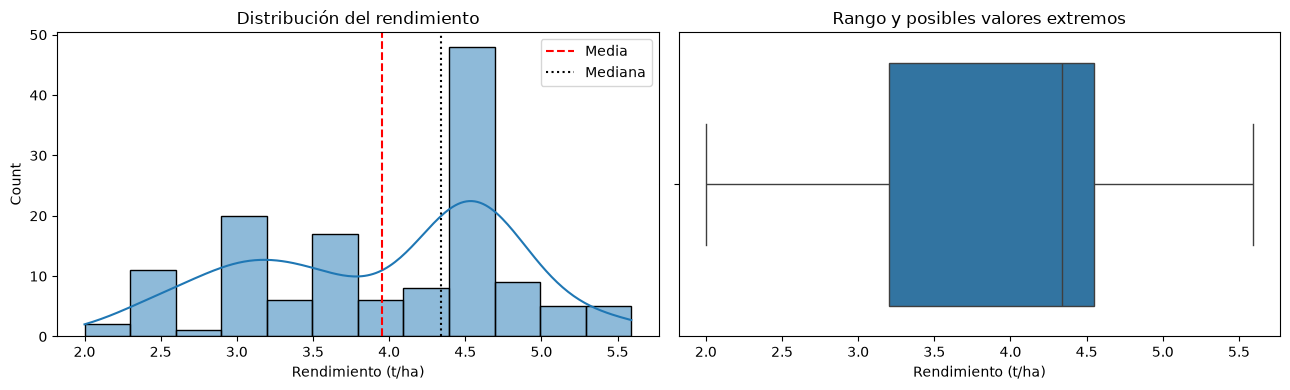

Media: 3.955
Mediana: 4.34
Desviación estándar: 0.851


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    data=resumen_limpio,
    x="rendimiento",
    bins=12,
    kde=True,
    ax=axes[0]
 )
axes[0].axvline(
    resumen_limpio["rendimiento"].mean(),
    color="red",
    linestyle="--",
    label="Media"
 )
axes[0].axvline(
    resumen_limpio["rendimiento"].median(),
    color="black",
    linestyle=":",
    label="Mediana"
 )
axes[0].set_title("Distribución del rendimiento")
axes[0].set_xlabel("Rendimiento (t/ha)")
axes[0].legend()

sns.boxplot(
    data=resumen_limpio,
    x="rendimiento",
    ax=axes[1]
 )
axes[1].set_title("Rango y posibles valores extremos")
axes[1].set_xlabel("Rendimiento (t/ha)")
plt.tight_layout()
plt.show()

print("Media:", round(resumen_limpio["rendimiento"].mean(), 3))
print("Mediana:", round(resumen_limpio["rendimiento"].median(), 3))
print("Desviación estándar:", round(resumen_limpio["rendimiento"].std(), 3))

**Cómo leer estos gráficos:** la media y la mediana cercanas sugieren una distribución relativamente equilibrada. La caja representa el 50% central de las parcelas; puntos alejados de los bigotes pueden ser atípicos, pero no deben eliminarse sin revisar la parcela y su contexto agrícola.

### 3. Separar datos y entrenar modelos base
Separamos parcelas, no filas satelitales. El conjunto de prueba contiene parcelas que el modelo nunca ve durante el entrenamiento. Usamos MAE y RMSE: ambos están en t/ha y cuanto menores sean, mejor. $R^2$ indica qué proporción de variabilidad explica el modelo, pero con 138 parcelas puede ser inestable.

In [26]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

caracteristicas = [
    "ndvi_media",
    "ndvi_maximo",
    "ndvi_minimo",
    "ndvi_std",
    "ndvi_ultimo",
    "ndvi_primer",
    "ndvi_delta",
    "ndvi_trend",
    "evi_media",
    "evi_maximo",
    "evi_minimo",
    "evi_ultimo",
    "lai_media",
    "lai_maximo",
    "lai_minimo",
    "lai_ultimo",
    "msavi_media",
    "msavi_maximo",
    "msavi_minimo",
    "msavi_ultimo",
    "nubosidad_media",
    "nubosidad_max",
    "observaciones_validas",
    "dias_observados",
    "area_ha"
]

modelo_data = resumen_limpio.dropna(subset=["rendimiento"]).copy()
for columna in modelo_data.columns:
    if columna not in ["ID_POLIGONO", "rendimiento"]:
        modelo_data[columna] = pd.to_numeric(modelo_data[columna], errors="coerce")

X = modelo_data[caracteristicas]
y = modelo_data["rendimiento"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

modelos = {
    "Media de referencia": Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("modelo", DummyRegressor(strategy="mean"))
    ]),
    "Regresion lineal": Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("escalado", StandardScaler()),
        ("modelo", LinearRegression())
    ]),
    "Random Forest": Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("modelo", RandomForestRegressor(
            n_estimators=500,
            max_depth=None,
            min_samples_leaf=2,
            random_state=42
        ))
    ]),
    "Extra Trees": Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("modelo", ExtraTreesRegressor(
            n_estimators=500,
            random_state=42
        ))
    ]),
    "HistGradientBoosting": Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("modelo", HistGradientBoostingRegressor(
            random_state=42,
            max_leaf_nodes=31
        ))
    ])
}

resultados = []
predicciones_test = {}
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    prediccion_test = modelo.predict(X_test)
    predicciones_test[nombre] = prediccion_test
    resultados.append({
        "modelo": nombre,
        "MAE": mean_absolute_error(y_test, prediccion_test),
        "RMSE": np.sqrt(mean_squared_error(y_test, prediccion_test)),
        "R2": r2_score(y_test, prediccion_test)
    })

resultados = pd.DataFrame(resultados).sort_values("MAE")
display(resultados.round(3))

cv = KFold(n_splits=5, shuffle=True, random_state=42)
validacion = []
for nombre, modelo in modelos.items():
    mae_cv = -cross_val_score(
        modelo, X, y, cv=cv, scoring="neg_mean_absolute_error"
    )
    mse_cv = -cross_val_score(
        modelo, X, y, cv=cv, scoring="neg_mean_squared_error"
    )
    validacion.append({
        "modelo": nombre,
        "MAE_CV_media": mae_cv.mean(),
        "MAE_CV_std": mae_cv.std(),
        "RMSE_CV_media": np.sqrt(mse_cv.mean())
    })

validacion = pd.DataFrame(validacion).sort_values("MAE_CV_media")
display(validacion.round(3))


,modelo,MAE,RMSE,R2
1,Regresion lineal,0.415,0.603,0.244
3,Extra Trees,0.453,0.614,0.216
2,Random Forest,0.474,0.640,0.149
4,HistGradientBoosting,0.502,0.728,-0.101
0,Media de referencia,0.675,0.774,-0.245


,modelo,MAE_CV_media,MAE_CV_std,RMSE_CV_media
3,Extra Trees,0.508,0.065,0.660
2,Random Forest,0.526,0.050,0.678
4,HistGradientBoosting,0.560,0.065,0.732
1,Regresion lineal,0.585,0.100,0.791
0,Media de referencia,0.758,0.089,0.859


### 4. Interpretar las predicciones y los errores
El modelo seleccionado para interpretar será el que tenga menor MAE promedio en validación cruzada. El gráfico ideal de predicción tiene los puntos cerca de la diagonal; los residuos deben quedar alrededor de cero sin formar patrones.

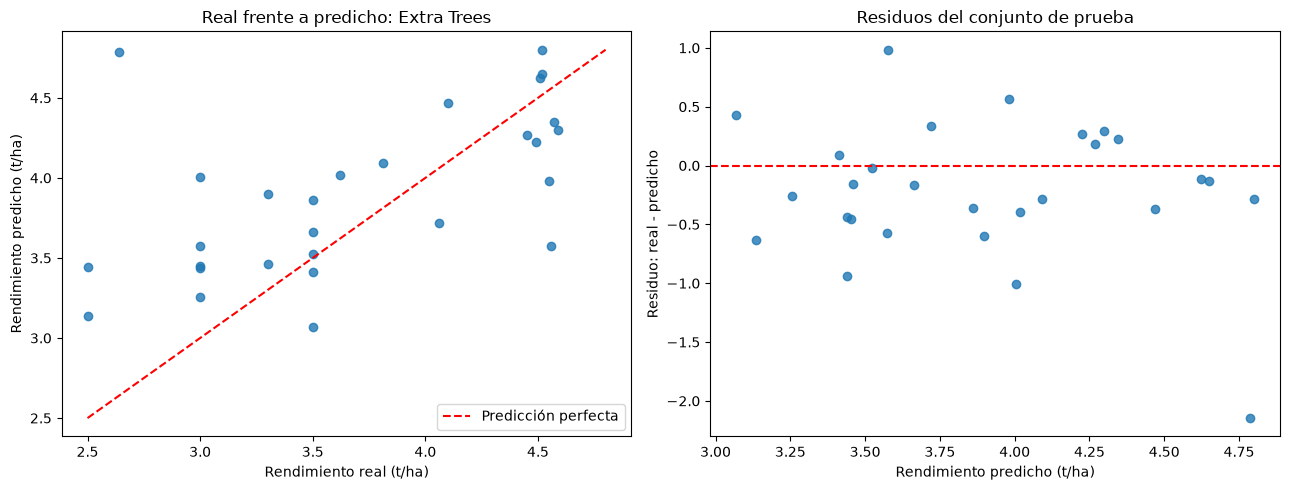

Modelo elegido por MAE de validación cruzada: Extra Trees
Error medio absoluto en prueba: 0.453 t/ha
Residuo medio: -0.212 t/ha


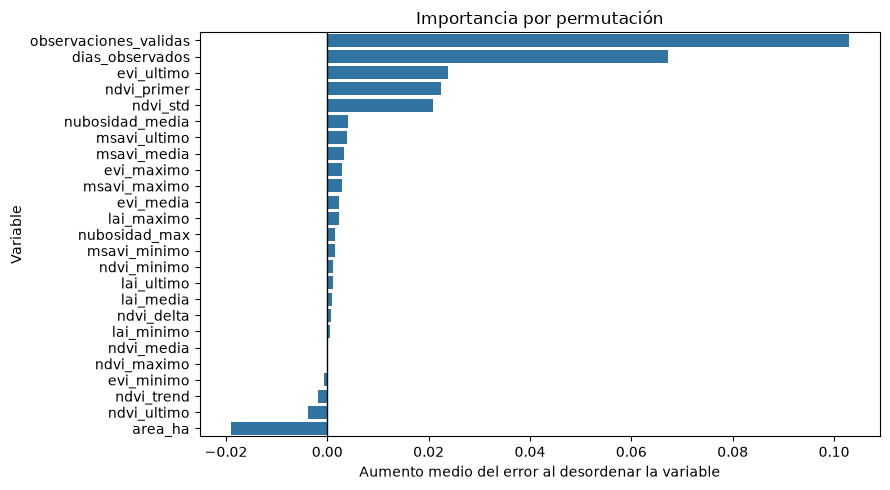

,variable,importancia_media,desviacion
22,observaciones_validas,0.1030,0.0375
23,dias_observados,0.0672,0.0289
11,evi_ultimo,0.0238,0.0177
5,ndvi_primer,0.0225,0.0165
3,ndvi_std,0.0209,0.0120
20,nubosidad_media,0.0040,0.0063
19,msavi_ultimo,0.0039,0.0073
16,msavi_media,0.0032,0.0030
9,evi_maximo,0.0030,0.0054
17,msavi_maximo,0.0028,0.0043


,variable,coeficiente
11,evi_ultimo,1.2404
16,msavi_media,1.1174
19,msavi_ultimo,-1.1120
18,msavi_minimo,-0.8592
8,evi_media,-0.8442
10,evi_minimo,0.8119
17,msavi_maximo,0.4773
0,ndvi_media,-0.3987
3,ndvi_std,-0.3931
15,lai_ultimo,0.3727


In [27]:
from sklearn.inspection import permutation_importance

mejor_nombre = validacion.iloc[0]["modelo"]
mejor_modelo = modelos[mejor_nombre]
prediccion_mejor = predicciones_test[mejor_nombre]
residuos = y_test.to_numpy() - prediccion_mejor

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, prediccion_mejor, alpha=0.8)
limite_inferior = min(y_test.min(), prediccion_mejor.min())
limite_superior = max(y_test.max(), prediccion_mejor.max())
axes[0].plot(
    [limite_inferior, limite_superior],
    [limite_inferior, limite_superior],
    "r--",
    label="Predicción perfecta"
)
axes[0].set_title(f"Real frente a predicho: {mejor_nombre}")
axes[0].set_xlabel("Rendimiento real (t/ha)")
axes[0].set_ylabel("Rendimiento predicho (t/ha)")
axes[0].legend()

axes[1].scatter(prediccion_mejor, residuos, alpha=0.8)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuos del conjunto de prueba")
axes[1].set_xlabel("Rendimiento predicho (t/ha)")
axes[1].set_ylabel("Residuo: real - predicho")
plt.tight_layout()
plt.show()

print("Modelo elegido por MAE de validación cruzada:", mejor_nombre)
print("Error medio absoluto en prueba:", round(mean_absolute_error(y_test, prediccion_mejor), 3), "t/ha")
print("Residuo medio:", round(residuos.mean(), 3), "t/ha")

importancia = permutation_importance(
    mejor_modelo,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="neg_mean_absolute_error"
)
importancia_df = pd.DataFrame({
    "variable": caracteristicas,
    "importancia_media": importancia.importances_mean,
    "desviacion": importancia.importances_std
}).sort_values("importancia_media", ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=importancia_df,
    x="importancia_media",
    y="variable"
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Importancia por permutación")
plt.xlabel("Aumento medio del error al desordenar la variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

display(importancia_df.round(4))

regresion = modelos["Regresion lineal"]
coeficientes = pd.DataFrame({
    "variable": caracteristicas,
    "coeficiente": regresion.named_steps["modelo"].coef_
}).sort_values("coeficiente", key=abs, ascending=False)
display(coeficientes.round(4))


**Lectura de estos resultados:**
- Un punto por debajo de la diagonal significa que el modelo sobreestima el rendimiento; por encima, lo subestima.
- En los residuos, una nube sin patrón alrededor de cero es deseable. Muchos residuos negativos en rendimientos altos indicarían sobreestimación sistemática.
- La importancia por permutación mide cuánto empeora el MAE cuando se desordena una variable. Un valor cercano a cero significa que el modelo casi no la necesita en esta muestra.
- La importancia no implica causalidad. `observaciones_validas`, por ejemplo, puede medir calidad de información y no una propiedad del cultivo.
- Los coeficientes de la regresión lineal muestran dirección, pero con índices muy correlacionados deben interpretarse con cautela.

In [28]:
errores_test = modelo_data.loc[X_test.index, ["ID_POLIGONO", "rendimiento"]].copy()
errores_test["prediccion"] = prediccion_mejor
errores_test["residuo"] = errores_test["rendimiento"] - errores_test["prediccion"]
errores_test["error_absoluto"] = errores_test["residuo"].abs()
errores_test = errores_test.sort_values("error_absoluto", ascending=False)

display(errores_test.head(10).round(3))

print(
    "Parcela con mayor error:",
    errores_test.iloc[0]["ID_POLIGONO"],
    "con error de",
    round(errores_test.iloc[0]["error_absoluto"], 3),
    "t/ha"
 )

,ID_POLIGONO,rendimiento,prediccion,residuo,error_absoluto
12,AGC_015,2.64,4.786,-2.146,2.146
67,AGC_098,3.00,4.005,-1.005,1.005
73,AGC_104,4.56,3.576,0.984,0.984
42,AGC_058,2.50,3.441,-0.941,0.941
117,AGC_166,2.50,3.135,-0.635,0.635
27,AGC_038,3.30,3.897,-0.597,0.597
56,AGC_078,3.00,3.574,-0.574,0.574
18,AGC_022,4.55,3.981,0.569,0.569
104,AGC_148,3.00,3.452,-0.452,0.452
19,AGC_023,3.00,3.440,-0.440,0.440


Parcela con mayor error: AGC_015 con error de 2.146 t/ha


### 5. Generar predicciones base
Después de comparar modelos, entrenamos el modelo seleccionado con todas las parcelas de entrenamiento. Las 59 parcelas `PREDICCION` no se usan para evaluar porque no tienen rendimiento conocido en este archivo.

In [29]:
resumen_prediccion = (
    prediccion_limpia
    .groupby("ID_POLIGONO")
    .agg(
        ndvi_media=("ndvi_promedio", "mean"),
        ndvi_maximo=("ndvi_promedio", "max"),
        ndvi_minimo=("ndvi_promedio", "min"),
        ndvi_std=("ndvi_promedio", "std"),
        ndvi_ultimo=("ndvi_promedio", lambda s: s.iloc[-1]),
        ndvi_primer=("ndvi_promedio", lambda s: s.iloc[0]),
        ndvi_delta=("ndvi_promedio", lambda s: s.iloc[-1] - s.iloc[0]),
        ndvi_trend=(
            "ndvi_promedio",
            lambda s: np.polyfit(np.arange(len(s)), s, 1)[0] if len(s) > 1 else 0
        ),
        evi_media=("evi_promedio", "mean"),
        evi_maximo=("evi_promedio", "max"),
        evi_minimo=("evi_promedio", "min"),
        evi_ultimo=("evi_promedio", lambda s: s.iloc[-1]),
        lai_media=("lai_promedio", "mean"),
        lai_maximo=("lai_promedio", "max"),
        lai_minimo=("lai_promedio", "min"),
        lai_ultimo=("lai_promedio", lambda s: s.iloc[-1]),
        msavi_media=("msavi_promedio", "mean"),
        msavi_maximo=("msavi_promedio", "max"),
        msavi_minimo=("msavi_promedio", "min"),
        msavi_ultimo=("msavi_promedio", lambda s: s.iloc[-1]),
        nubosidad_media=("porcentaje_nubosidad", "mean"),
        nubosidad_max=("porcentaje_nubosidad", "max"),
        observaciones_validas=("ndvi_promedio", "count"),
        area_ha=("AREA_HA", "first"),
        fecha_inicio=("fecha_captura", "min"),
        fecha_fin=("fecha_captura", "max")
    )
    .reset_index()
)

resumen_prediccion["dias_observados"] = (
    resumen_prediccion["fecha_fin"] - resumen_prediccion["fecha_inicio"]
).dt.days + 1
resumen_prediccion = resumen_prediccion.drop(columns=["fecha_inicio", "fecha_fin"])

for columna in resumen_prediccion.columns:
    if columna not in ["ID_POLIGONO"]:
        resumen_prediccion[columna] = pd.to_numeric(resumen_prediccion[columna], errors="coerce")

modelo_final = modelos[mejor_nombre]
modelo_final.fit(X, y)
predicciones_59 = modelo_final.predict(
    resumen_prediccion[caracteristicas]
)

resultado_predicciones = resumen_prediccion[[
    "ID_POLIGONO", "area_ha"
]].copy()
resultado_predicciones["rendimiento_predicho_t_ha"] = predicciones_59
resultado_predicciones = resultado_predicciones.sort_values(
    "rendimiento_predicho_t_ha"
)

print("Parcelas predichas:", len(resultado_predicciones))
display(resultado_predicciones.head(10).round(3))


Parcelas predichas: 59


,ID_POLIGONO,area_ha,rendimiento_predicho_t_ha
7,AGC_030,13.05,3.098
10,AGC_039,7.71,3.142
42,AGC_147,6.80,3.217
6,AGC_029,5.90,3.244
31,AGC_113,10.58,3.303
24,AGC_087,5.66,3.309
4,AGC_027,8.46,3.340
46,AGC_156,8.20,3.341
33,AGC_118,4.42,3.382
13,AGC_050,2.42,3.464


In [30]:
salida_predicciones = (
    resultado_predicciones
    .merge(
        rendimiento[["ID_POLIGONO", "CONJUNTO"]],
        on="ID_POLIGONO",
        how="left"
    )
 )
salida_predicciones.to_csv(
    "predicciones_modelo_base_PRO.csv",
    index=False,
    encoding="utf-8-sig"
 )

print("Archivo guardado: predicciones_modelo_base_PRO.csv")
print(
    "Rendimiento predicho mínimo:",
    round(salida_predicciones["rendimiento_predicho_t_ha"].min(), 3),
    "t/ha"
 )
print(
    "Rendimiento predicho máximo:",
    round(salida_predicciones["rendimiento_predicho_t_ha"].max(), 3),
    "t/ha"
 )
print(
    "Rendimiento predicho promedio:",
    round(salida_predicciones["rendimiento_predicho_t_ha"].mean(), 3),
    "t/ha"
 )

Archivo guardado: predicciones_modelo_base_PRO.csv
Rendimiento predicho mínimo: 3.098 t/ha
Rendimiento predicho máximo: 4.938 t/ha
Rendimiento predicho promedio: 3.965 t/ha


## Conclusión de la línea base
El primer modelo ya funciona como referencia. Su error es aproximadamente de medio tonelada por hectárea, por lo que todavía no debe usarse como decisión agrícola definitiva. El siguiente paso será comparar este resultado con variables temporales por etapa del cultivo y después añadir clima y topografía. Las parcelas con mayor error deben revisarse primero en sus series NDVI y en QGIS.

## Diagnóstico inicial del conjunto BÁSICO

El conjunto BÁSICO se revisa antes de unirlo al modelo. Aunque comparte `ID_POLIGONO` con PRO y con la tabla objetivo, sus índices no tienen la misma cobertura en todos los sensores. Por eso se mantienen separados en esta primera etapa.

El siguiente bloque mide el número de filas, sensores, fechas, parcelas coincidentes y cobertura de índices. Su objetivo es decidir qué variables pueden agregarse sin interpretar un valor faltante como ausencia de vegetación.


In [31]:
ruta_basico = "DATASET_RETO_AGRO_2026/Conjunto_datos_BASICO_AgroCebada2026.csv"
basico = pd.read_csv(ruta_basico)
basico["fecha_captura"] = pd.to_datetime(
    basico["fecha_captura"],
    dayfirst=True,
    errors="coerce"
)

indices_basico = [
    columna for columna in basico.columns
    if columna.endswith("_promedio")
]

resumen_basico_sensor = (
    basico
    .groupby("sensor")
    .agg(
        filas=("ID_POLIGONO", "size"),
        parcelas=("ID_POLIGONO", "nunique"),
        fecha_inicio=("fecha_captura", "min"),
        fecha_fin=("fecha_captura", "max"),
        filas_con_algun_indice=(
            "ID_POLIGONO",
            lambda serie: basico.loc[serie.index, indices_basico]
            .notna()
            .any(axis=1)
            .sum()
        )
    )
    .reset_index()
)

cobertura_indices_sensor = (
    basico
    .groupby("sensor")[indices_basico]
    .apply(lambda bloque: bloque.notna().mean())
    .round(3)
)

parcelas_basico = set(basico["ID_POLIGONO"].dropna())
parcelas_objetivo = set(rendimiento["ID_POLIGONO"].dropna())

print("Filas BÁSICO:", len(basico))
print("Parcelas BÁSICO:", basico["ID_POLIGONO"].nunique())
print("Sensores:", basico["sensor"].value_counts(dropna=False).to_dict())
print("Parcelas coincidentes con objetivo:", len(parcelas_basico & parcelas_objetivo))
print("\nResumen por sensor:")
display(resumen_basico_sensor)
print("\nCobertura de índices promedio por sensor:")
display(cobertura_indices_sensor)


Filas BÁSICO: 107666
Parcelas BÁSICO: 197
Sensores: {'Sentinel-2': 59040, 'Landsat': 48626}
Parcelas coincidentes con objetivo: 197

Resumen por sensor:


,sensor,filas,parcelas,fecha_inicio,fecha_fin,filas_con_algun_indice
0,Landsat,48626,197,2022-01-05,2025-12-31,31048
1,Sentinel-2,59040,197,2022-01-01,2025-12-31,44877



Cobertura de índices promedio por sensor:


,ndvi_promedio,evi_promedio,crc_promedio,mcrc_promedio,ndsvi_promedio,srndi_promedio,mra_promedio,lai_promedio,fapar_promedio,savi_promedio,...,ndwi_promedio,endwi_promedio,msi_promedio,emsi_promedio,dswi2_promedio,dswi3_promedio,dswi4_promedio,dswi5_promedio,nddi_promedio,enddi_promedio
sensor,,,,,,,,,,,,,,,,,,,,,
Landsat,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Sentinel-2,0.76,0.76,0.76,0.76,0.76,0.76,0.76,0.76,0.76,0.76,...,0.76,0.76,0.76,0.76,0.76,0.76,0.76,0.76,0.76,0.76


## Comparación de sensores BÁSICO

La comparación se realizó en `compare_basico_sentinel.py` usando las features temporales completas de PRO, las mismas 138 parcelas y validación cruzada de cinco pliegues.

- PRO 2025: MAE promedio `0.508`, RMSE promedio `0.653`.
- PRO 2025 + Sentinel-2 2025: MAE promedio `0.490`, RMSE promedio `0.638`.
- PRO 2025 + Landsat VI6T 2025: MAE promedio `0.454`, RMSE promedio `0.598`.

Landsat + `VI6T` fue el mejor candidato de la comparación de sensores, aunque posteriormente se evaluó de nuevo con validación repetida.

El archivo `predicciones_modelo_PRO_sensores.csv` contiene 59 parcelas y tres predicciones por parcela:

- `rendimiento_predicho_pro_2025`: referencia PRO.
- `rendimiento_predicho_pro_sentinel2_2025`: candidato enriquecido con Sentinel-2.
- `rendimiento_predicho_pro_landsat_2025`: candidato enriquecido con Landsat y `VI6T`.

## Ingeniería espacial: clima y topografía

El script `compare_all_features.py` extrae promedios zonales de los raster de 2025 para cada parcela. Se utiliza `all_touched=True` porque las parcelas pequeñas pueden no contener el centro de ningún píxel climático. La extracción fue auditada y produjo `0` valores espaciales faltantes.

La validación repetida de 5 pliegues por 5 repeticiones produjo:

- PRO: MAE `0.510`, RMSE `0.660`.
- PRO + Landsat: MAE `0.454`, RMSE `0.601`.
- PRO + Landsat + Sentinel-2: MAE `0.464`, RMSE `0.612`.
- PRO + Landsat + Sentinel-2 + clima: MAE `0.389`, RMSE `0.528`.
- PRO + Landsat + Sentinel-2 + clima + topografía: MAE `0.392`, RMSE `0.530`.

El candidato actual es PRO + Landsat + Sentinel-2 + clima. La topografía queda como bloque experimental porque no redujo el error en esta validación.

El modelo completo genera `predicciones_modelo_completo.csv` para las 59 parcelas de predicción.

## Optimización y confianza de las predicciones

`optimize_model.py` compara Extra Trees, Random Forest y Gradient Boosting mediante validación cruzada repetida. El mejor resultado corresponde a Random Forest con `min_samples_leaf=4` y `max_features=0.7`:

- MAE repetido `0.378`.
- RMSE repetido `0.518`.
- R² fuera de muestra `0.602`.

La ablación climática confirmó que la señal no depende únicamente de una partición: el MAE sube a `0.398` al quitar precipitación de mayo y a `0.492` al quitar todo el clima.

El archivo `predicciones_modelo_optimizado.csv` añade incertidumbre por bootstrap mediante desviación estándar e intervalos P10-P90. Este modelo utiliza el clima completo de 2025, por lo que estima el rendimiento al cierre del ciclo. Para predicción anticipada se deberán entrenar modelos con fechas de corte.


## Validación robusta para parcelas nuevas

El script `final_model_pipeline.py` compara variables actuales, features del ciclo agrícola y tres modelos mediante validación aleatoria repetida y validación espacial por grupos. La validación espacial es la referencia más conservadora para aplicar el modelo en parcelas diferentes.

El mejor resultado espacial fue:

- Modelo: Gradient Boosting.
- Features: PRO + Landsat + Sentinel-2 + clima.
- MAE espacial: `0.638` t/ha.
- RMSE espacial: `0.814` t/ha.
- R² espacial: `0.078`.

La validación aleatoria es mejor, pero puede ser optimista cuando parcelas próximas comparten condiciones. Por eso el archivo recomendado para revisar predicciones nuevas es `predicciones_modelo_robusto.csv`, que contiene el valor puntual a cuatro decimales, la desviación bootstrap y los intervalos P10-P90.

Las parcelas con confianza relativa baja deben revisarse antes de tomar decisiones agronómicas. El modelo actual estima el rendimiento al cierre del ciclo 2025; para predicción temprana se deben eliminar las variables posteriores a la fecha de corte.


## Precisión frente a parcelas conocidas

La precisión se calculó con predicciones fuera de muestra sobre las 138 parcelas con rendimiento real.

| Validación | MAE | RMSE | MAPE | Dentro de +/-10% | Dentro de +/-20% | Dentro de +/-0.5 t/ha |
|---|---:|---:|---:|---:|---:|---:|
| Aleatoria | 0.409 | 0.577 | 11.7% | 65.2% | 85.5% | 72.5% |
| Espacial | 0.638 | 0.814 | 19.6% | 42.0% | 63.8% | 50.7% |

La validación espacial es la referencia conservadora para aplicar el modelo a parcelas nuevas. En regresión no existen falsos positivos y negativos directos; se controlan mediante error absoluto, sesgo, tolerancias e intervalos de incertidumbre.

El archivo `precision_modelo_parcelas_conocidas.csv` conserva estas métricas.
